In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Load and inspect data

In [2]:
# Option A: Load the Seaborn Titanic dataset
df = sns.load_dataset("titanic")

# Option B: If you downloaded Kaggle's train.csv, comment out the line above and use:
# df = pd.read_csv("train.csv")

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Dataset shape:", df.shape)
print("\\nColumn information:")
df.info()


Dataset shape: (891, 15)
\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
print("Descriptive statistics (numeric columns):")
display(df.describe())

print("\\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False))

print("\\nSurvival counts:")
display(df["survived"].value_counts(dropna=False))

print("\\nSurvival proportions:")
display(df["survived"].value_counts(normalize=True, dropna=False).round(3))


Descriptive statistics (numeric columns):


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


\nMissing values by column:


,0
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


\nSurvival counts:


,count
survived,
0,549
1,342


\nSurvival proportions:


,proportion
survived,
0,0.616
1,0.384


Data Quality and preparation

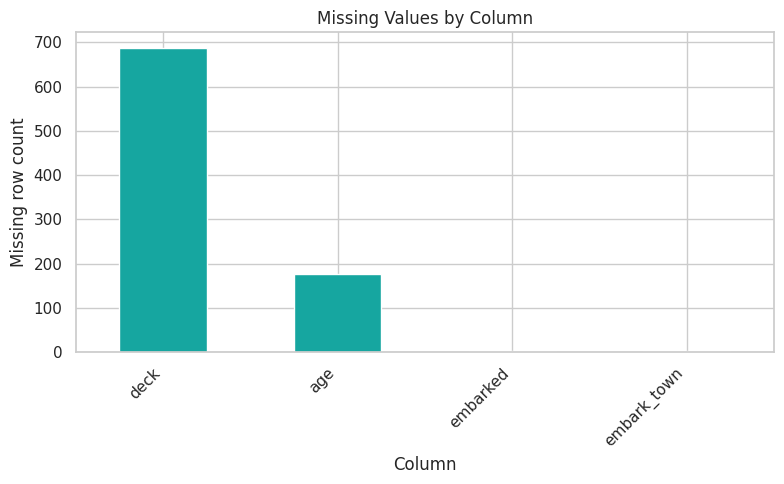

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

if len(missing):
    missing.plot(kind="bar", color="#16A6A0")
    plt.title("Missing Values by Column")
    plt.ylabel("Missing row count")
    plt.xlabel("Column")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


Univariate Analysis

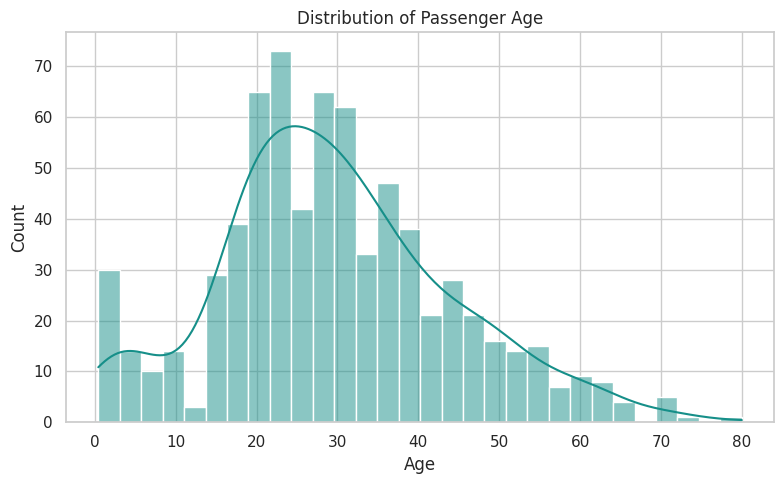

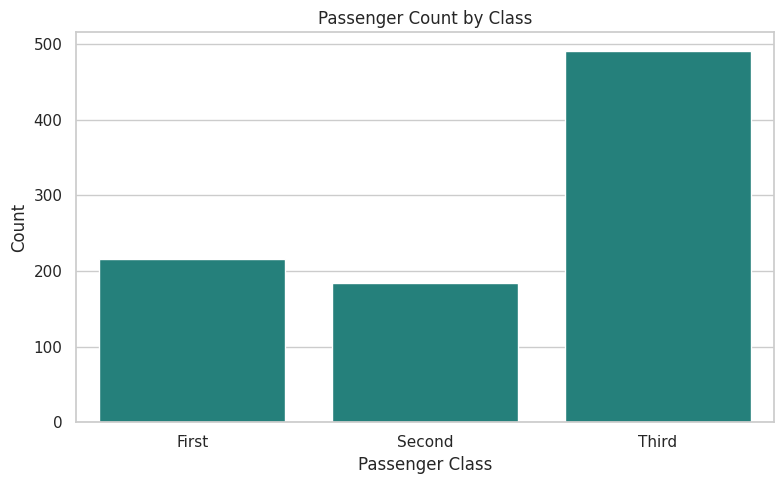

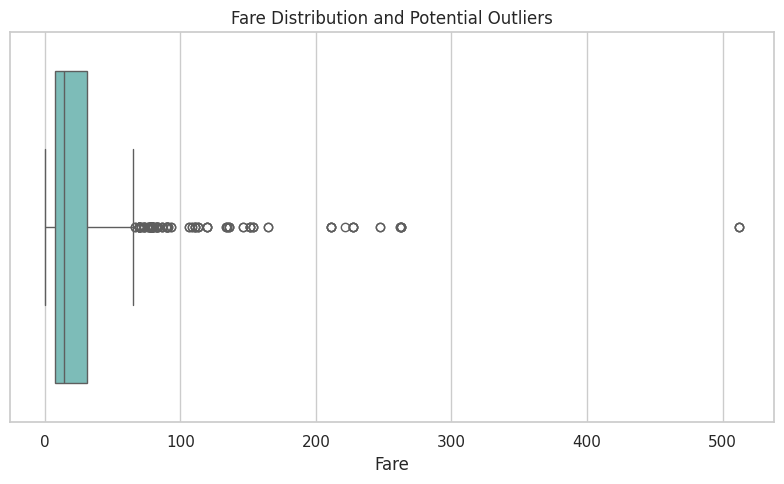

In [6]:
# Distribution of age
sns.histplot(data=df, x="age", bins=30, kde=True, color="#168F89")
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

# Passenger class counts
sns.countplot(data=df, x="class", color="#168F89", order=["First", "Second", "Third"])
plt.title("Passenger Count by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Fare outliers
sns.boxplot(data=df, x="fare", color="#72C7C1")
plt.title("Fare Distribution and Potential Outliers")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()


**Observations to record after running:**
- The age distribution is concentrated among younger and middle-aged passengers, with fewer older passengers.
- Passenger counts differ by class; the third class is typically the largest group in this dataset.
- Fare is usually right-skewed, with high-fare outliers. Consider a log scale when comparing the full fare distribution.

Biavariate Analysis

,survived
sex,
female,0.742038
male,0.188908


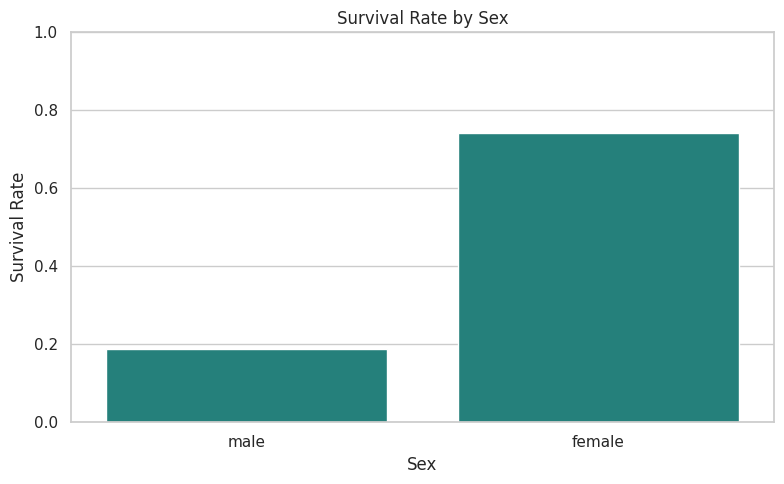

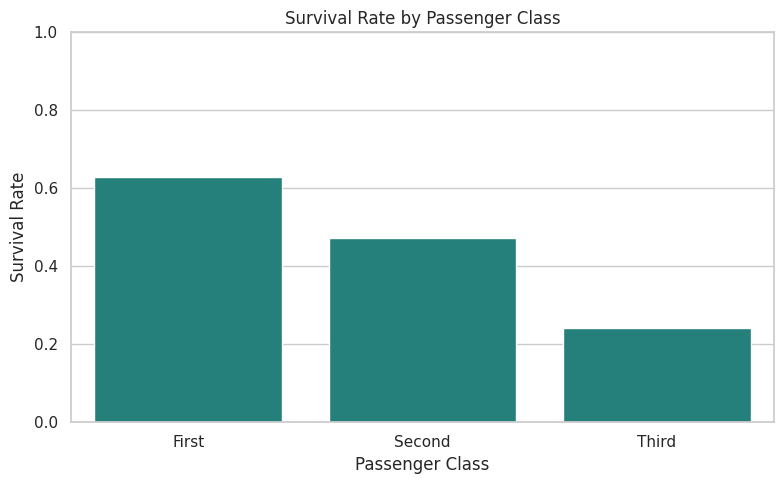

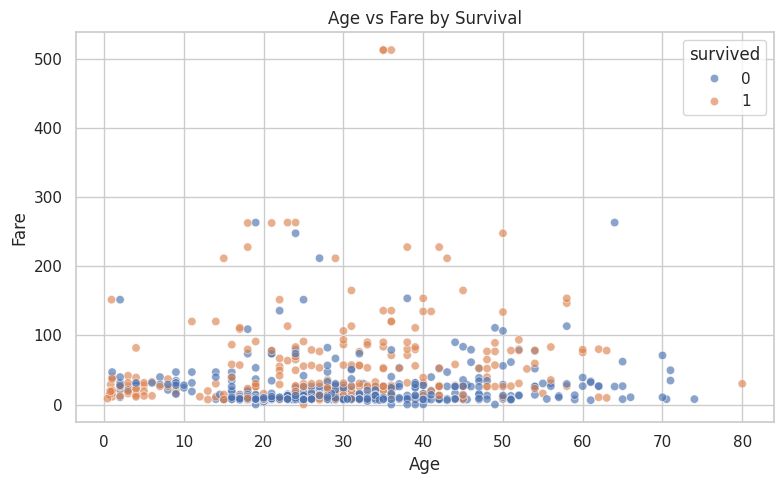

In [7]:
# Survival rate by sex
survival_by_sex = df.groupby("sex", observed=False)["survived"].mean().sort_values(ascending=False)
display(survival_by_sex)

sns.barplot(data=df, x="sex", y="survived", errorbar=None, color="#168F89")
plt.title("Survival Rate by Sex")
plt.ylabel("Survival Rate")
plt.xlabel("Sex")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Survival rate by passenger class
sns.barplot(data=df, x="class", y="survived", errorbar=None, order=["First", "Second", "Third"], color="#168F89")
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.xlabel("Passenger Class")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Age and fare relationship, colored by survival
sns.scatterplot(data=df, x="age", y="fare", hue="survived", alpha=0.65)
plt.title("Age vs Fare by Survival")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()


**Observations to record after running:**
- Survival rates differ by sex; women generally had a higher survival rate than men.
- First-class passengers generally had higher survival rates than third-class passengers.
- The age–fare scatterplot may show clusters by fare and class, with some high-fare outliers. A relationship in a plot does not by itself prove causation.

Multivariate Analysis and Correlation

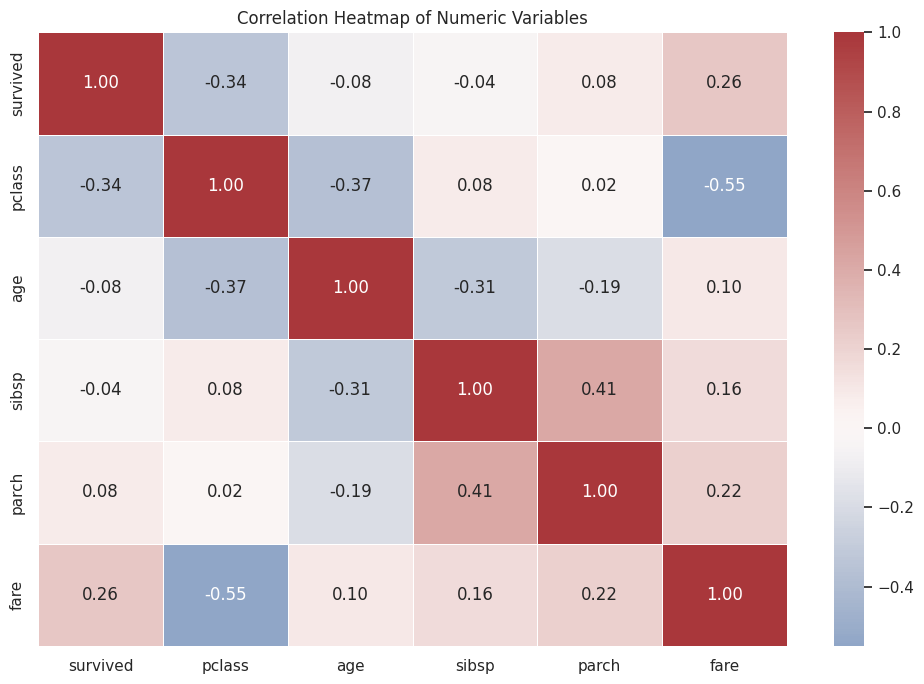

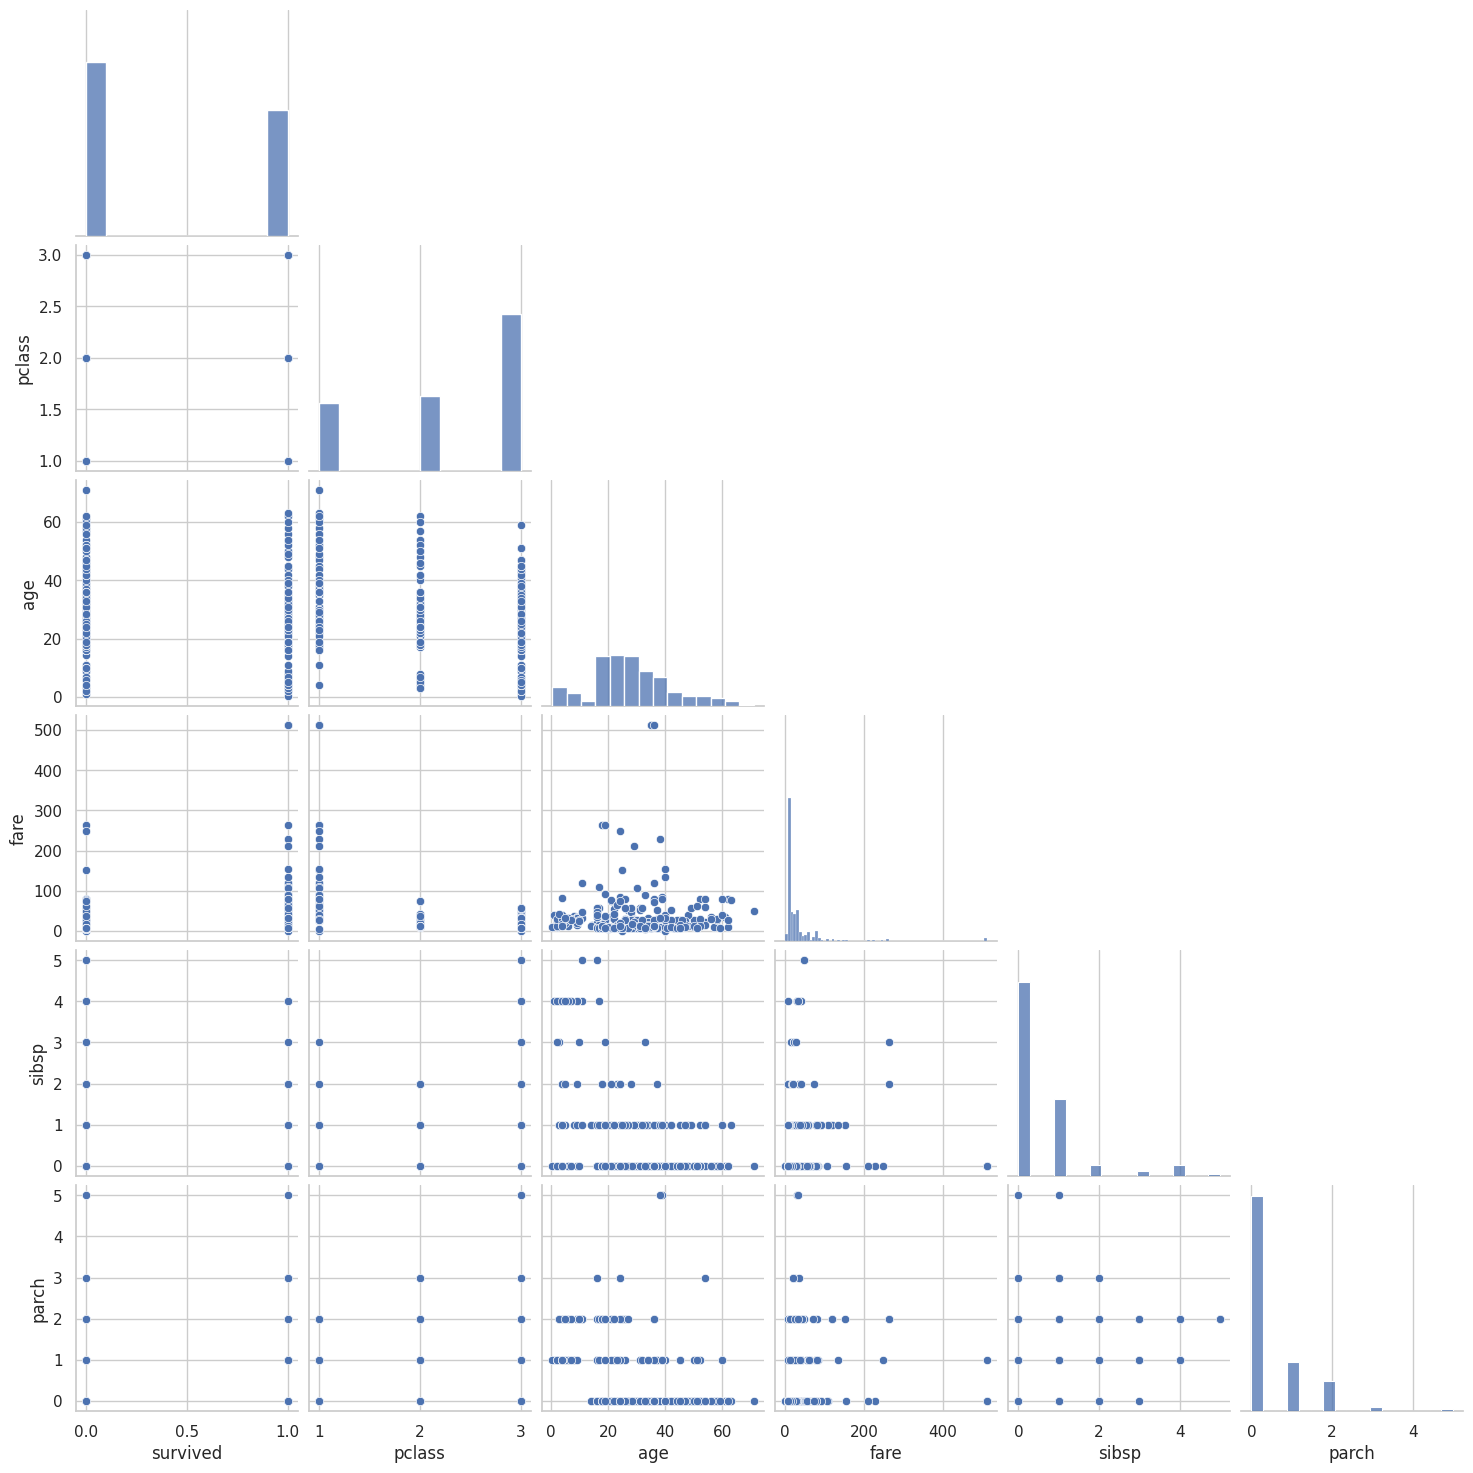

In [8]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

# Pairplot on a small subset to keep the plot readable
pair_cols = [c for c in ["survived", "pclass", "age", "fare", "sibsp", "parch"] if c in df.columns]
pair_df = df[pair_cols].dropna()
sns.pairplot(pair_df.sample(min(300, len(pair_df)), random_state=42), corner=True, diag_kind="hist")
plt.show()


**Interpretation guidance:**
- Correlation values near +1 indicate a strong positive linear association; values near -1 indicate a strong negative linear association; values near 0 indicate weak linear association.
- Correlation does not imply causation.
- `pclass` is ordinal, and correlations involving it should be interpreted with care.
- Pairplots show pairwise distributions and relationships; heatmaps summarize numeric correlations in a compact matrix.

6. Outlier check


In [9]:
for col in ["age", "fare"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = s[(s < lower) | (s > upper)]
    print(f"{col}: {len(outliers)} potential IQR outliers out of {len(s)} non-missing values")


age: 11 potential IQR outliers out of 714 non-missing values
fare: 116 potential IQR outliers out of 891 non-missing values


## 7. Summary of findings

1. Survival was not evenly distributed across passenger groups.
2. Sex and passenger class show clear associations with survival in the dataset.
3. Age contains missing observations, so analyses involving age use fewer records unless a missing-data strategy is applied.
4. Fare is strongly right-skewed and contains high-value outliers; report median and quartiles as well as the mean.
5. Correlation heatmaps and pairplots help identify patterns, but results are descriptive and do not establish causality.

## 8. Question quick notes

- **EDA:** the process of inspecting, cleaning, summarizing, and visualizing data before formal modeling.
- **Correlation plots:** scatterplots for two numeric variables; heatmaps for a matrix of correlations; pairplots for multiple pairwise relationships.
- **Skewed data:** consider median/IQR, transformations such as `log1p`, robust methods, and whether the skew is meaningful.
- **Multicollinearity:** inspect correlation matrices and use Variance Inflation Factor (VIF) for regression predictors.
- **Univariate / bivariate / multivariate:** one variable / relationship between two variables / three or more variables together.
- **Heatmap vs pairplot:** heatmap summarizes correlation values; pairplot visualizes distributions and pairwise patterns.
- **Summarizing insights:** connect each chart to a clear observation, caveat, and possible next question.

## Reproducibility note
Record the dataset source and version used. Dataset variants may differ in column names and missing values.